# Statistiques de coco

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/EmbeddedComputervision/blob/main/notebooks/coco/coco_stats.ipynb)

Présentation et analyse statistique du jeu, lues du point de vue de Tiny-YOLO et de la
cible embarquée (entrée 416, grilles 13×13 et 26×26, 256 emplacements de `yolo_post`,
INT8). Tâches : [T11.1](../../docs/tasks/M11-jeux-de-donnees.md), [T16.13](../../docs/tasks/M16-presentation-jeux.md), [T16.4](../../docs/tasks/M16-presentation-jeux.md) ; jalon : [M16](../../docs/tasks/M16-presentation-jeux.md) ;
synthèse : [stats-jeux.md](../../docs/tasks/stats-jeux.md). Autres notebooks du jeu :
[tiny-yolov3-coco_infer](tiny-yolov3-coco_infer.ipynb), [tiny-yolov4-coco_infer](tiny-yolov4-coco_infer.ipynb), [tiny-yolov7-coco_infer](tiny-yolov7-coco_infer.ipynb), [yolov5n-coco_infer](yolov5n-coco_infer.ipynb), [yolov8n-coco_infer](yolov8n-coco_infer.ipynb).

Palier : annotations **R** (split entier), pixels **M** (`SAMPLE = 200`
images par partie). Prérequis : données `data/coco/annotations/instances_val2017.json` — tools/get_datasets.sh coco. Ni poids ni GPU.

Question propre : Quelle part des objets est petite (< 32²) une fois réduite à 416 ? (renvoi : T11.1).

| | |
|---|---|
| source | https://cocodataset.org |
| version | 2017 (val2017, train2017 ; calib2017 de tools/coco_subset.py) |
| licence | annotations CC BY 4.0, images Flickr (conditions de Flickr) |
| capteur | photos Flickr, scènes encombrées, couleur |
| résolution typique | ≈ 640×480 |
| officiel `val2017` | 5000 images, 36781 objets |
| officiel `train2017` | 118287 images, 860001 objets |
| officiel `calib2017` | — images, — objets |
| chargeur | boîtes gardées sans rognage (`clip=False`, comme COCOeval) |
| chargeur | `iscrowd` en `difficult` et `crowd` |
| chargeur | calib2017 : 500 images annotées de train2017 (tools/coco_subset.py) |

Aucun calcul ici : `tools/data_stats.py` calcule (`stats.json`, `stats.md`, galerie),
`tools/figures/donnees.py` trace ; chaque étape affiche la commande. Sorties dans
`build/notebooks/coco/stats/`, jamais dans `results/`. Notebook généré par `python -m tools.notebooks`
(`make notebooks`) : modifier `tools/notebooks/gabarits.py`, pas ce fichier.

## Paramètres

In [1]:
DATASET   = 'coco'  # clé de DATASETS
SPLITS    = None  # liste de splits ; None : splits train puis test du jeu
SIZE      = None  # S ou 'LxH' ; None : entrée de la cfg du jeu (416 sinon)
RESIZE    = 'letterbox'  # letterbox | stretch (grandeurs vues par le réseau)
SAMPLE    = 200  # images lues pour les pixels, par partie ; 0 : aucune
GALLERY   = 8  # images de la galerie par split
SEED      = 0  # tirage des images (pixels, galerie, nuages)
NET       = 'tiny-yolov3-coco'  # cfg dont les ancres et grilles servent aux collisions
DEVICE    = 'cpu'  # noyau CPU : rien ne tourne sur GPU
DATA_ROOT = None  # racine du jeu ; None : data/<jeu> (Colab : dossier Drive)
DRIVE_DIR = '/content/drive/MyDrive/EmbeddedCV'  # Colab : archives data/<jeu>.tar ; None : pas de Drive
OUT       = 'build/notebooks/coco/stats'  # sorties du notebook
REPO_URL  = 'https://github.com/lrivals/EmbeddedComputervision.git'  # Colab : dépôt cloné
REV       = 'main'  # Colab : révision

## Environnement

Local : rien n'est installé ni téléchargé, la cellule vérifie les prérequis et
s'arrête avec la commande à lancer. Colab : clone du dépôt, installation, CuPy si
`DEVICE = "gpu"`, poids, puis données par `colab.prepare_data` (archive
`<DRIVE_DIR>/data/<jeu>.tar` ou téléchargement direct ; ExDark et FLIR : archive
seulement, faite sur le PC par `tools/get_datasets.sh pack <jeu>`).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

COLAB = "google.colab" in sys.modules


def repo_root():
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "tools" / "notebooks" / "commandes.py").exists():
            return d
    return None


ROOT = repo_root()
if COLAB:
    if ROOT is None:
        ROOT = Path("/content/EmbeddedComputervision")
        if not ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    # Clone d'une session précédente : remis à REV (notebook et code du même commit).
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "FETCH_HEAD"], check=True)
    for m in [m for m in sys.modules if m.split(".")[0] in ("tools", "yolo")]:
        del sys.modules[m]  # modules importés avant la mise à jour
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}/python[data,plots]"], check=True)
    if DEVICE == "gpu":
        # Runtime CPU : pas de pilote, CuPy dirait « cudaErrorInsufficientDriver ».
        try:
            smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
        except FileNotFoundError:
            smi = None
        if smi is None or smi.returncode != 0:
            raise RuntimeError("runtime Colab sans GPU : créer un nouveau serveur Colab "
                               "de type GPU (T4, L4 ou A100), ou DEVICE = 'cpu'")
        cuda = smi.stdout.split("CUDA Version:")[-1].split()[0]  # version du pilote
        cupy_pkg = "cupy-cuda13x" if int(cuda.split(".")[0]) >= 13 else "cupy-cuda12x"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cupy_pkg],
                       check=True)
elif ROOT is None:
    raise RuntimeError("racine du dépôt introuvable : ouvrir le notebook depuis notebooks/")
os.chdir(ROOT)
for p in (ROOT, ROOT / "python"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tools.notebooks import commandes as C
from tools.notebooks import env

TRACE = env.trace(DEVICE)
env.check_device(DEVICE)
env.prepare(DATASET, (), None, DATA_ROOT, COLAB, hint='',
            drive_dir=DRIVE_DIR)
if str(NET).endswith(".cfg") and not env.restore_cfg(NET):
    print(f"cfg {NET} absente (tools/m11.sh {DATASET}-prep) : ancres et grilles de "
          "tiny-yolov3-coco pour les collisions")
    NET = "tiny-yolov3-coco"
Path(OUT).mkdir(parents=True, exist_ok=True)

dépôt /home/leonard/Documents/Perso/EmbeddedComputervision @ 3263136 (modifié) ; Python 3.12.3 ; NumPy 2.4.2 ; backend cpu
données coco : data/coco/annotations/instances_val2017.json ; poids : —


## Calcul (T16.0)

`tools/data_stats.py` lit les annotations de chaque split (en entier), lit les pixels
de `SAMPLE` images par partie (tirées avec `SEED`), dessine la galerie et trace les
figures. Les grandeurs « vues par le réseau » sont calculées après `RESIZE` à `SIZE`.

In [3]:
import json

from IPython.display import Image as Img, Markdown, display

from tools import data_stats as DS
from tools.notebooks.matrice import SPLIT_IMAGES, palier_stats
from yolo.models.tiny_yolo import load_cfg

if SIZE is None:
    _, h, w = load_cfg(NET)["input"]
    SIZE = h if h == w else f"{w}x{h}"
ann, px = palier_stats(DATASET, SAMPLE)
print(f"palier : annotations {ann}, pixels {px} ({SAMPLE} images par partie) ; "
      f"entrée {SIZE} ({RESIZE}) ; cfg {NET}")
C.run(C.cmd_data_stats(DATASET, OUT, SPLITS, SIZE, RESIZE, NET, SAMPLE, GALLERY, SEED,
                       data_root=DATA_ROOT))
STATS = json.loads(Path(OUT, "stats.json").read_text())
FIG = Path(OUT, "figures")


def show(name):
    png = FIG / f"{name}.png"
    if png.exists():
        display(Img(filename=str(png)))


def table(fn):
    text = fn(STATS)
    if text:
        display(Markdown(text))

palier : annotations R, pixels M (200 images par partie) ; entrée 416 (letterbox) ; cfg tiny-yolov3-coco
$ python tools/data_stats.py --dataset coco --size 416 --resize letterbox --net tiny-yolov3-coco --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/coco/stats


chargement coco train2017…


chargement coco val2017…


analyses train2017 (118287 images)…


analyses val2017 (5000 images)…


...

→ build/notebooks/coco/stats/figures/intensites.png


→ build/notebooks/coco/stats/figures/ancres.png


→ build/notebooks/coco/stats/figures/ancres_k.png


→ build/notebooks/coco/stats/figures/ecart.png


  (843 s)


## Présentation et galerie (T16.4)

Classes du jeu et leur correspondance VOC et COCO (`MAPPINGS`), puis `GALLERY` images
par split, une image par classe ; vérités terrain dessinées par `tools/detect.py:draw`.
À `SEED` fixé, la galerie ne change pas.

| classe | VOC | COCO |
|---|---|---|
| person | person | person |
| bicycle | bicycle | bicycle |
| car | car | car |
| motorbike | motorbike | motorbike |
| aeroplane | aeroplane | aeroplane |
| bus | bus | bus |
| train | train | train |
| truck | — | truck |
| boat | boat | boat |
| traffic light | — | traffic light |
| fire hydrant | — | fire hydrant |
| stop sign | — | stop sign |
| parking meter | — | parking meter |
| bench | — | bench |
| bird | bird | bird |
| cat | cat | cat |
| dog | dog | dog |
| horse | horse | horse |
| sheep | sheep | sheep |
| cow | cow | cow |
| elephant | — | elephant |
| bear | — | bear |
| zebra | — | zebra |
| giraffe | — | giraffe |
| backpack | — | backpack |
| umbrella | — | umbrella |
| handbag | — | handbag |
| tie | — | tie |
| suitcase | — | suitcase |
| frisbee | — | frisbee |
| skis | — | skis |
| snowboard | — | snowboard |
| sports ball | — | sports ball |
| kite | — | kite |
| baseball bat | — | baseball bat |
| baseball glove | — | baseball glove |
| skateboard | — | skateboard |
| surfboard | — | surfboard |
| tennis racket | — | tennis racket |
| bottle | bottle | bottle |
| wine glass | — | wine glass |
| cup | — | cup |
| fork | — | fork |
| knife | — | knife |
| spoon | — | spoon |
| bowl | — | bowl |
| banana | — | banana |
| apple | — | apple |
| sandwich | — | sandwich |
| orange | — | orange |
| broccoli | — | broccoli |
| carrot | — | carrot |
| hot dog | — | hot dog |
| pizza | — | pizza |
| donut | — | donut |
| cake | — | cake |
| chair | chair | chair |
| sofa | sofa | sofa |
| pottedplant | pottedplant | pottedplant |
| bed | — | bed |
| diningtable | diningtable | diningtable |
| toilet | — | toilet |
| tvmonitor | tvmonitor | tvmonitor |
| laptop | — | laptop |
| mouse | — | mouse |
| remote | — | remote |
| keyboard | — | keyboard |
| cell phone | — | cell phone |
| microwave | — | microwave |
| oven | — | oven |
| toaster | — | toaster |
| sink | — | sink |
| refrigerator | — | refrigerator |
| book | — | book |
| clock | — | clock |
| vase | — | vase |
| scissors | — | scissors |
| teddy bear | — | teddy bear |
| hair drier | — | hair drier |
| toothbrush | — | toothbrush |

galerie : val2017


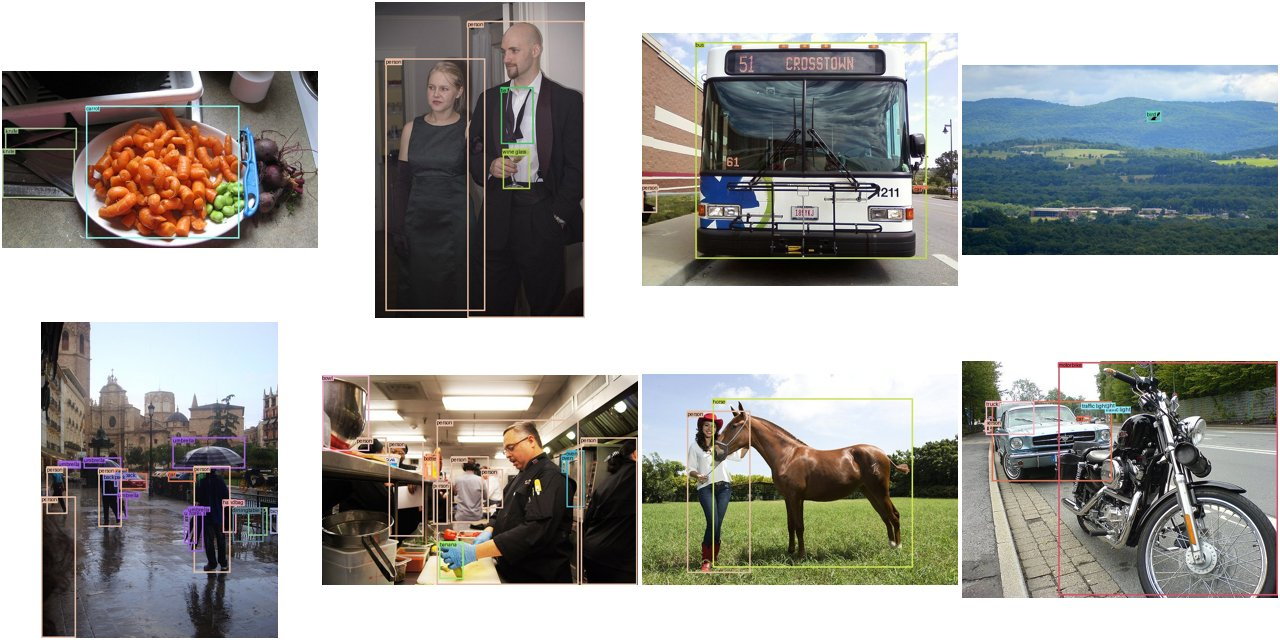

galerie : classes


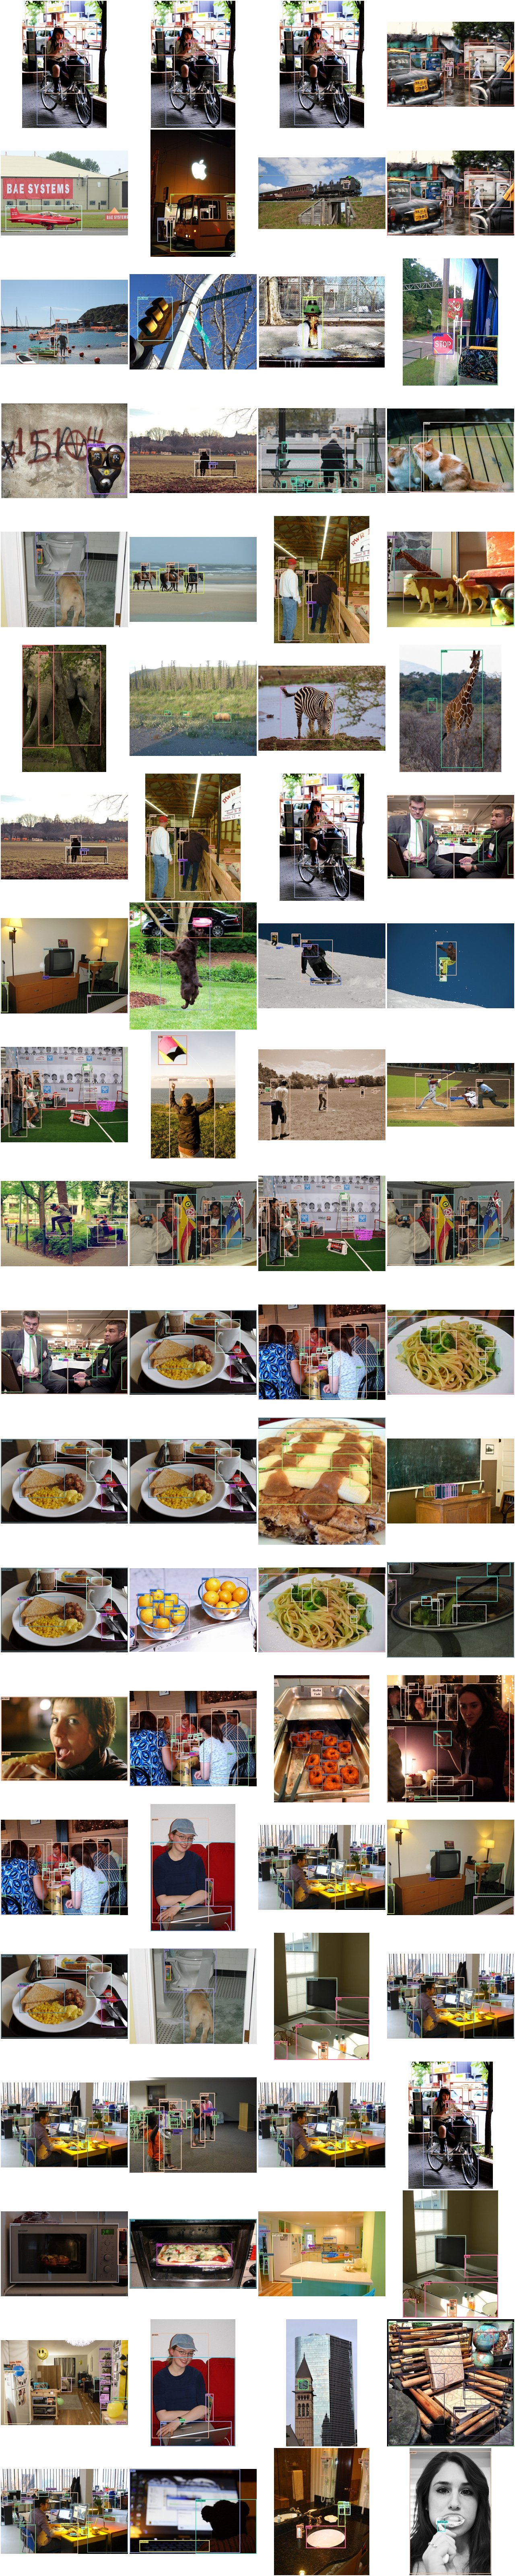

In [4]:
from yolo.data import datasets as D

rows = ["| classe | VOC | COCO |", "|---|---|---|"]
for c in D.DATASETS[DATASET].classes:
    m = [c if DATASET == f else D.MAPPINGS.get((DATASET, f), {}).get(c, "—")
         for f in ("voc", "coco")]
    rows.append(f"| {c} | {m[0]} | {m[1]} |")
display(Markdown("\n".join(rows)))
for g, sheet in STATS.get("galerie", {}).get("planches", {}).items():
    if g != "suspectes":
        print(f"galerie : {g}")
        display(Img(filename=str(Path(OUT, sheet))))

## Comptes et classes (T16.5)

Comptes par split (annotations, split entier), face aux effectifs officiels de la
fiche ; objets par classe et co-occurrence.

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train2017 | 118 287 | 860 001 | 10 052 | 1 021 | 4 / 93 | 44,3 % | 13x13 33,8 % · 26x26 14,6 % | 25,83 % | 0 / 0 |
| val2017 | 5 000 | 36 781 | 446 | 48 | 4 / 63 | 44,5 % | 13x13 34,1 % · 26x26 14,2 % | 25,61 % | 0 / 0 |
| ensemble | 123 287 | 896 782 | 10 498 | 1 069 | 4 / 93 | 44,3 % | 13x13 33,8 % · 26x26 14,6 % | 25,82 % | 0 / 0 |

val2017 : 5000 images, 36781 objets ; officiel 5000 / 36781 : ok
train2017 : 118287 images, 860001 objets ; officiel 118287 / 860001 : ok


| classe | train2017 : objets (images) | val2017 : objets (images) | côté médian (px, letterbox) | petits |
|---|---|---|---|---|
| person | 262 465 (64 115) | 11 004 (2 693) | 40 | 43 % |
| bicycle | 7 113 (3 252) | 316 (149) | 40 | 42 % |
| car | 43 867 (12 251) | 1 932 (535) | 21 | 67 % |
| motorbike | 8 725 (3 502) | 371 (159) | 61 | 28 % |
| aeroplane | 5 135 (2 986) | 143 (97) | 95 | 20 % |
| bus | 6 069 (3 952) | 285 (189) | 97 | 17 % |
| train | 4 571 (3 588) | 190 (157) | 162 | 4 % |
| truck | 9 973 (6 127) | 415 (250) | 48 | 35 % |
| boat | 10 759 (3 025) | 430 (121) | 29 | 54 % |
| traffic light | 12 884 (4 139) | 637 (191) | 12 | 85 % |
| fire hydrant | 1 865 (1 711) | 101 (86) | 77 | 27 % |
| stop sign | 1 983 (1 734) | 75 (69) | 54 | 36 % |
| parking meter | 1 285 (705) | 60 (37) | 31 | 51 % |
| bench | 9 838 (5 570) | 413 (235) | 43 | 40 % |
| bird | 10 806 (3 237) | 440 (125) | 19 | 64 % |
| cat | 4 768 (4 114) | 202 (184) | 165 | 3 % |
| dog | 5 508 (4 385) | 218 (177) | 108 | 13 % |
| horse | 6 587 (2 941) | 273 (128) | 75 | 23 % |
| sheep | 9 509 (1 529) | 361 (65) | 34 | 48 % |
| cow | 8 147 (1 968) | 380 (87) | 39 | 43 % |
| elephant | 5 513 (2 143) | 255 (89) | 92 | 16 % |
| bear | 1 294 (960) | 71 (49) | 143 | 5 % |
| zebra | 5 303 (1 916) | 268 (85) | 90 | 15 % |
| giraffe | 5 131 (2 546) | 232 (101) | 130 | 6 % |
| backpack | 8 720 (5 528) | 371 (228) | 30 | 54 % |
| umbrella | 11 431 (3 968) | 413 (174) | 40 | 42 % |
| handbag | 12 354 (6 841) | 540 (292) | 25 | 60 % |
| tie | 6 496 (3 810) | 254 (145) | 28 | 55 % |
| suitcase | 6 192 (2 402) | 303 (105) | 56 | 27 % |
| frisbee | 2 682 (2 184) | 115 (84) | 26 | 62 % |
| skis | 6 646 (3 082) | 241 (120) | 31 | 51 % |
| snowboard | 2 685 (1 654) | 69 (49) | 40 | 43 % |
| sports ball | 6 347 (4 262) | 263 (169) | 10 | 91 % |
| kite | 9 076 (2 261) | 336 (91) | 17 | 69 % |
| baseball bat | 3 276 (2 506) | 146 (97) | 36 | 44 % |
| baseball glove | 3 747 (2 629) | 148 (100) | 20 | 78 % |
| skateboard | 5 543 (3 476) | 179 (127) | 40 | 39 % |
| surfboard | 6 126 (3 486) | 269 (149) | 42 | 40 % |
| tennis racket | 4 812 (3 394) | 225 (167) | 44 | 33 % |
| bottle | 24 342 (8 501) | 1 025 (379) | 21 | 69 % |
| wine glass | 7 913 (2 533) | 343 (110) | 28 | 56 % |
| cup | 20 650 (9 189) | 899 (390) | 26 | 58 % |
| fork | 5 479 (3 555) | 215 (155) | 35 | 46 % |
| knife | 7 770 (4 326) | 326 (181) | 26 | 57 % |
| spoon | 6 165 (3 529) | 253 (153) | 26 | 58 % |
| bowl | 14 358 (7 111) | 626 (314) | 42 | 40 % |
| banana | 9 458 (2 243) | 379 (103) | 40 | 41 % |
| apple | 5 851 (1 586) | 239 (76) | 33 | 49 % |
| sandwich | 4 373 (2 365) | 177 (98) | 98 | 17 % |
| orange | 6 399 (1 699) | 287 (85) | 36 | 46 % |
| broccoli | 7 308 (1 939) | 316 (71) | 55 | 22 % |
| carrot | 7 852 (1 683) | 371 (81) | 34 | 46 % |
| hot dog | 2 918 (1 222) | 127 (51) | 56 | 29 % |
| pizza | 5 821 (3 166) | 285 (153) | 105 | 17 % |
| donut | 7 179 (1 523) | 338 (62) | 44 | 37 % |
| cake | 6 353 (2 925) | 316 (124) | 61 | 25 % |
| chair | 38 491 (12 774) | 1 791 (580) | 39 | 42 % |
| sofa | 5 779 (4 423) | 261 (195) | 129 | 2 % |
| pottedplant | 8 652 (4 452) | 343 (172) | 43 | 36 % |
| bed | 4 192 (3 682) | 163 (149) | 220 | 1 % |
| diningtable | 15 714 (11 837) | 697 (501) | 161 | 14 % |
| toilet | 4 157 (3 353) | 179 (149) | 102 | 5 % |
| tvmonitor | 5 805 (4 561) | 288 (207) | 74 | 13 % |
| laptop | 4 970 (3 524) | 231 (183) | 91 | 14 % |
| mouse | 2 262 (1 876) | 106 (88) | 24 | 67 % |
| remote | 5 703 (3 076) | 283 (145) | 19 | 73 % |
| keyboard | 2 855 (2 115) | 153 (106) | 64 | 19 % |
| cell phone | 6 434 (4 803) | 262 (214) | 23 | 63 % |
| microwave | 1 673 (1 547) | 55 (54) | 58 | 19 % |
| oven | 3 334 (2 877) | 143 (115) | 96 | 6 % |
| toaster | 225 (217) | 9 (8) | 36 | 39 % |
| sink | 5 610 (4 678) | 225 (187) | 51 | 30 % |
| refrigerator | 2 637 (2 360) | 126 (101) | 124 | 2 % |
| book | 24 715 (5 332) | 1 161 (230) | 19 | 75 % |
| clock | 6 334 (4 659) | 267 (204) | 26 | 59 % |
| vase | 6 613 (3 593) | 277 (137) | 34 | 48 % |
| scissors | 1 481 (947) | 36 (28) | 62 | 30 % |
| teddy bear | 4 793 (2 140) | 191 (94) | 85 | 14 % |
| hair drier | 198 (189) | 11 (9) | 39 | 39 % |
| toothbrush | 1 954 (1 007) | 57 (34) | 26 | 57 % |

Rapport classe la plus / la moins fréquente : 1 308.

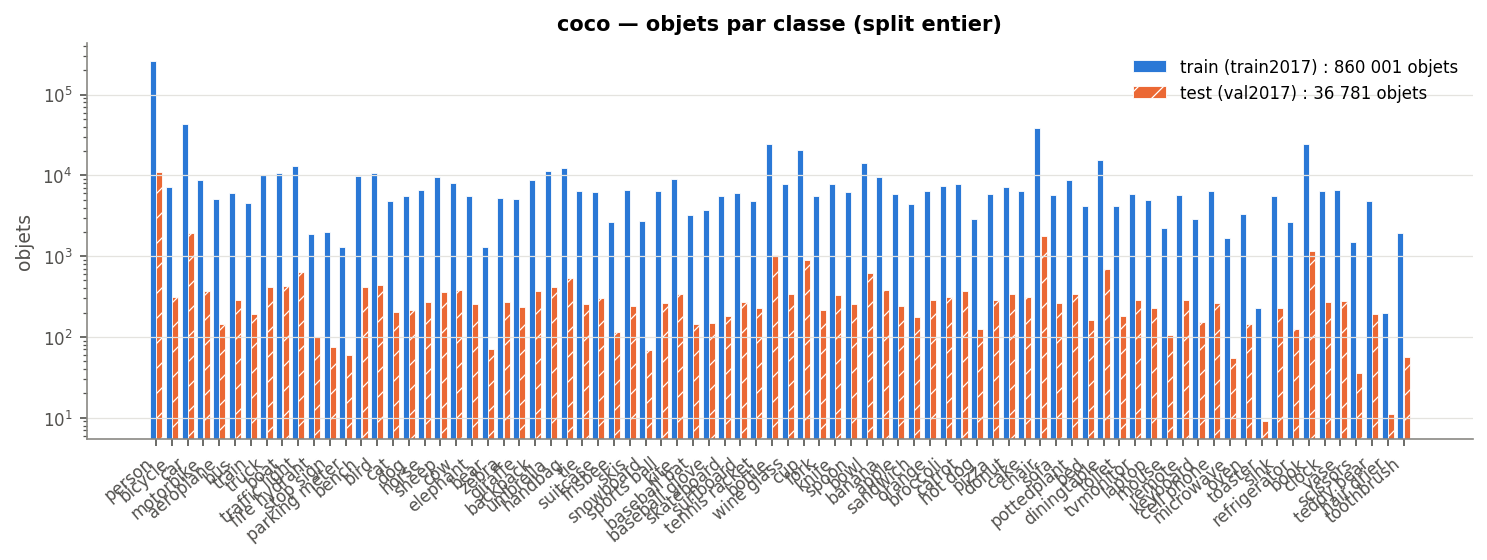

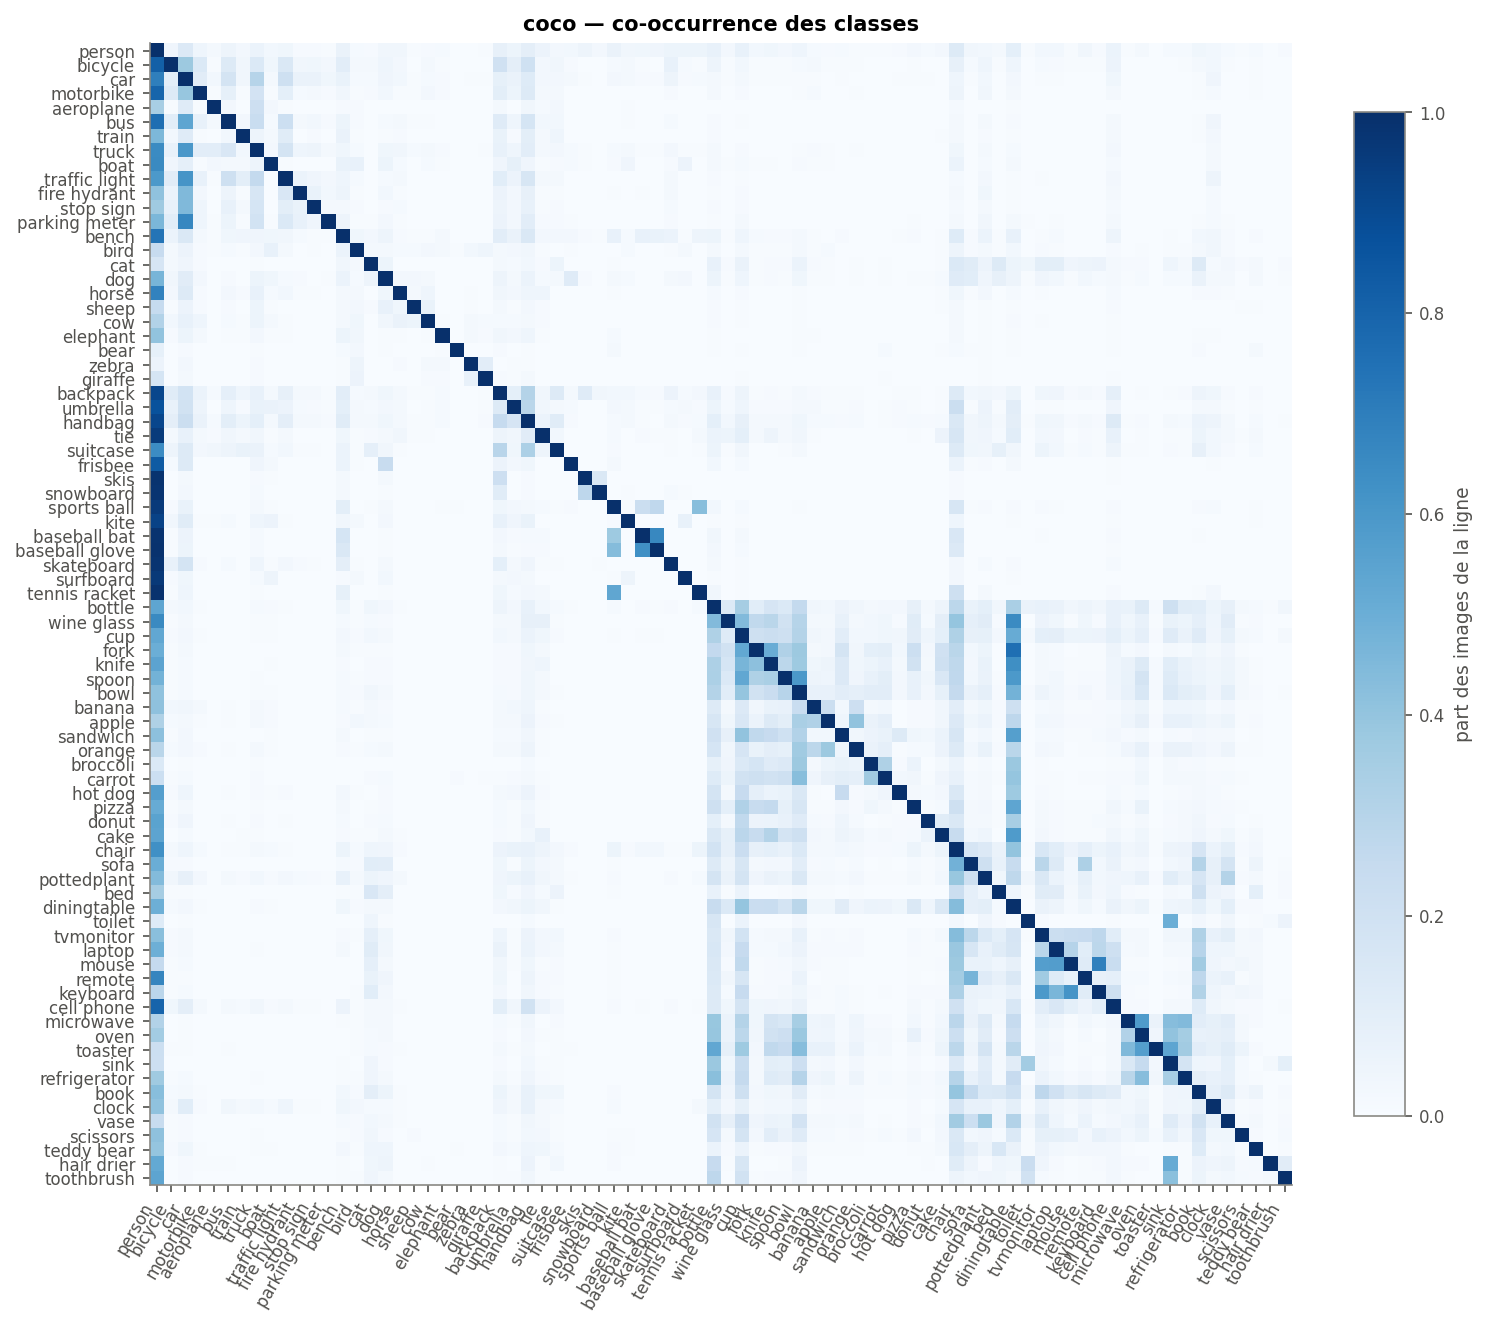

In [5]:
table(DS.md_synthese)
chk = DS.check_official(STATS)
for sp, i, o, (a, b), ok in chk:
    print(f"{sp} : {i} images, {o} objets ; officiel {a or '—'} / {b or '—'} : "
          f"{'ok' if ok else 'écart (voir les notes de la fiche)'}")
table(DS.md_classes)
show("classes")
show("cooccurrence")

## Géométrie des boîtes (T16.6)

Tailles en pixels d'origine et d'entrée (letterbox et stretch à `SIZE`), catégories
COCO avant et après redimensionnement, part des objets plus petits qu'une cellule de
chaque tête, centres des boîtes.

| repère | petits | moyens | grands | côté médian (px) | plus petits qu'une cellule | hauteur < 8 px |
|---|---|---|---|---|---|---|
| image d'origine | 31,5 % | 35,2 % | 33,4 % | 57 | — | — |
| letterbox 416×416 | 44,3 % | 33,4 % | 22,3 % | 38 | 13x13 33,8 % · 26x26 14,6 % | 7,5 % |
| stretch 416×416 | 38,6 % | 34,6 % | 26,8 % | 45 | 13x13 27,0 % · 26x26 10,1 % | 4,3 % |

886 284 objets non-difficult ; pas des têtes : 13x13 → 32 px, 26x26 → 16 px.

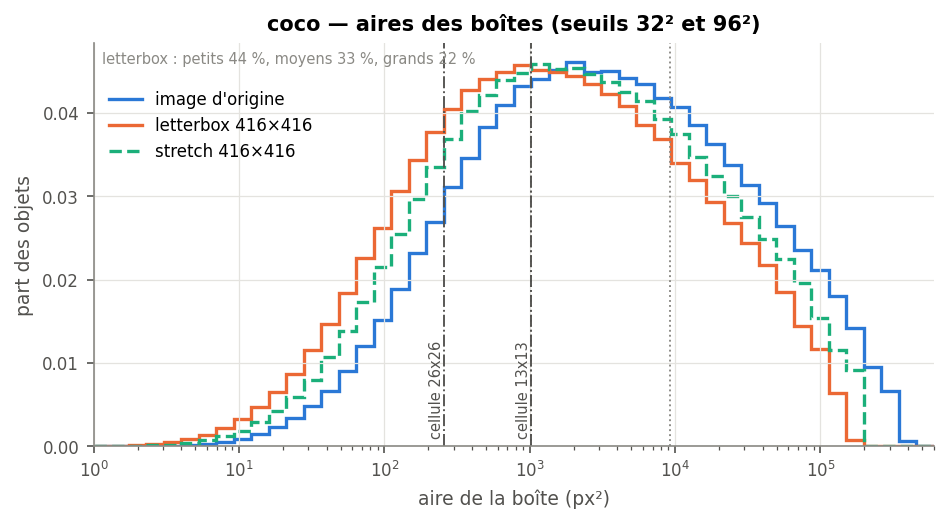

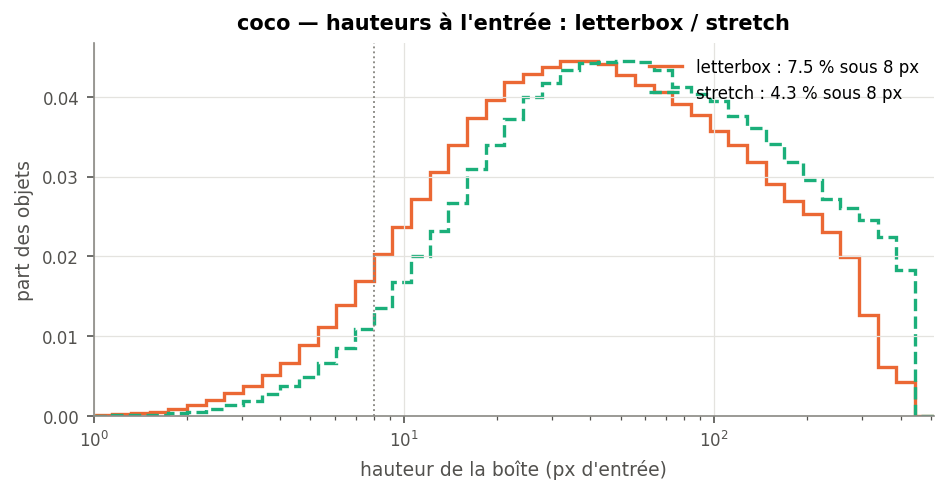

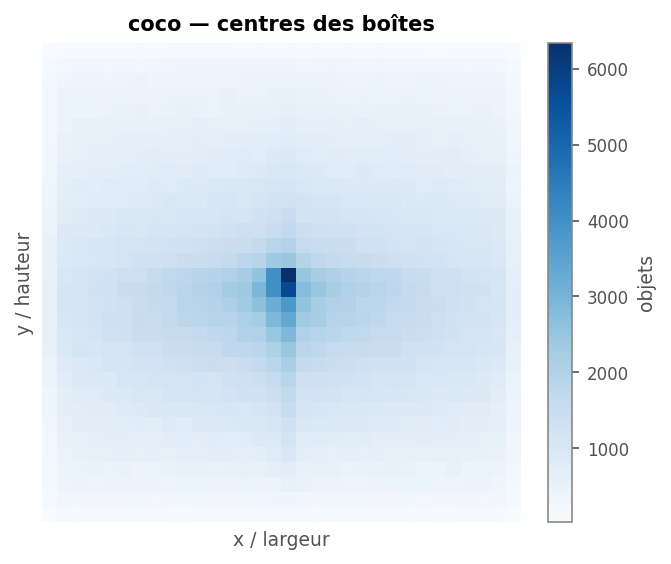

In [6]:
table(DS.md_geometrie)
show("tailles")
show("letterbox_stretch")
show("centres")

## Densité et collisions (T16.7)

Objets par image face aux 256 emplacements de `yolo_post` ; cibles perdues quand deux
objets tombent sur la même cellule et la même ancre (`build_targets`, ancres de `NET`).

| partie | objets/image moy. | méd. | max | > 256 / > 1 024 | cibles perdues | par tête (perdues / objets) | images touchées |
|---|---|---|---|---|---|---|---|
| train2017 | 7,3 | 4 | 93 | 0 / 0 | 219 539 / 849 947 (25,83 %) | 13x13 : 2 296 / 160 327 · 26x26 : 9 891 / 482 268 | 47 217 |
| val2017 | 7,4 | 4 | 63 | 0 / 0 | 9 305 / 36 335 (25,61 %) | 13x13 : 112 / 6 821 · 26x26 : 413 / 20 734 | 1 993 |
| ensemble | 7,3 | 4 | 93 | 0 / 0 | 228 844 / 886 282 (25,82 %) | 13x13 : 2 408 / 167 148 · 26x26 : 10 304 / 503 002 | 49 210 |

Ancres de `tiny-yolov3-coco` ; objets non-difficult, comme à l'entraînement.

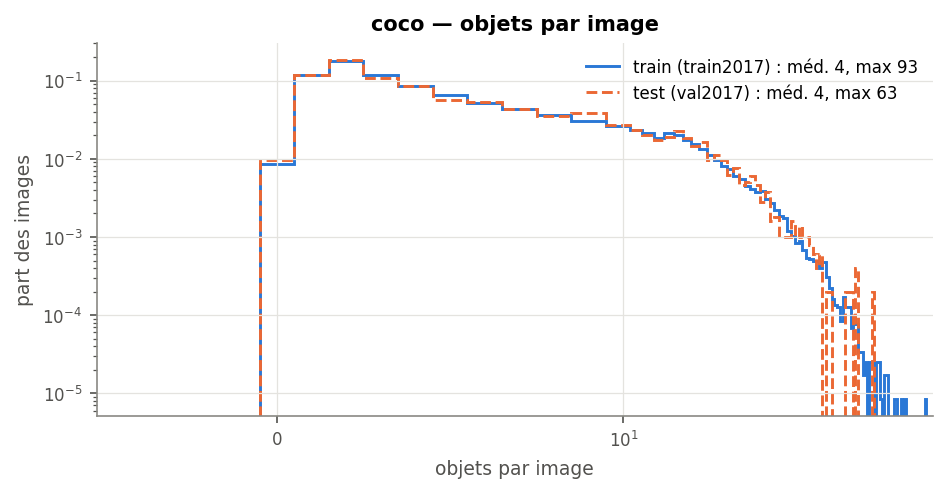

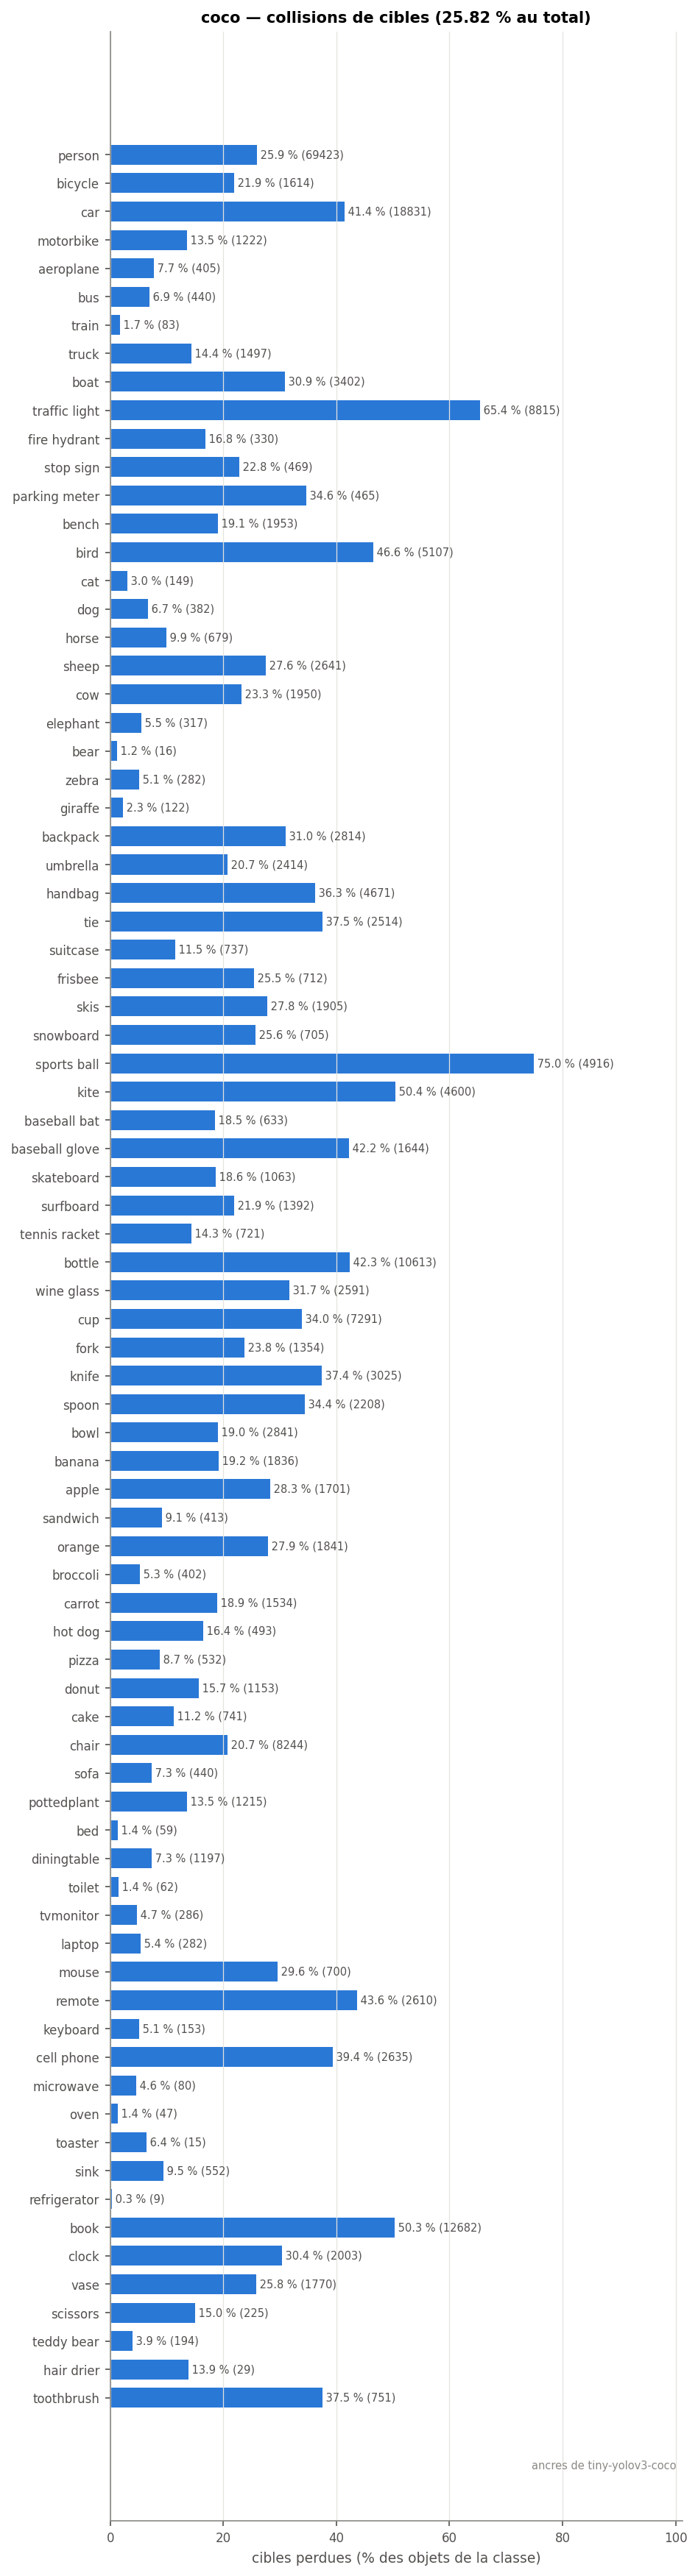

In [7]:
table(DS.md_densite)
show("densite")
show("collisions")

## Images (T16.8)

Résolutions sur le split entier (annotations) ; canaux, intensités et luminance sur
`SAMPLE` images par partie, face à VOC2007 test (échelles INT8 de M4).

| partie | résolutions (3 premières) | distinctes | pixels sur | canaux | moyenne par canal | écart type par canal | luminance moy. | niveaux 8 bits → INT8 |
|---|---|---|---|---|---|---|---|---|
| train2017 | 640×480 (25 403), 640×427 (14 596), 480×640 (8 411) | 2 477 | — | — | — | — | — | — |
| val2017 | 640×480 (1 061), 640×427 (606), 480×640 (336) | 603 | 200 images | 3 | 116,2 / 111,7 / 103,2 | 71,6 / 70,6 / 74,2 | 111,4 | 256 → 128 |
| ensemble | 640×480 (26 464), 640×427 (15 202), 480×640 (8 747) | 2 519 | 200 images | 3 | 116,2 / 111,7 / 103,2 | 71,6 / 70,6 / 74,2 | 111,4 | 256 → 128 |

Référence VOC2007 test (200 images, graine 0) : luminance moyenne 107,7, moyenne par canal 112,1 / 107,1 / 98,5.

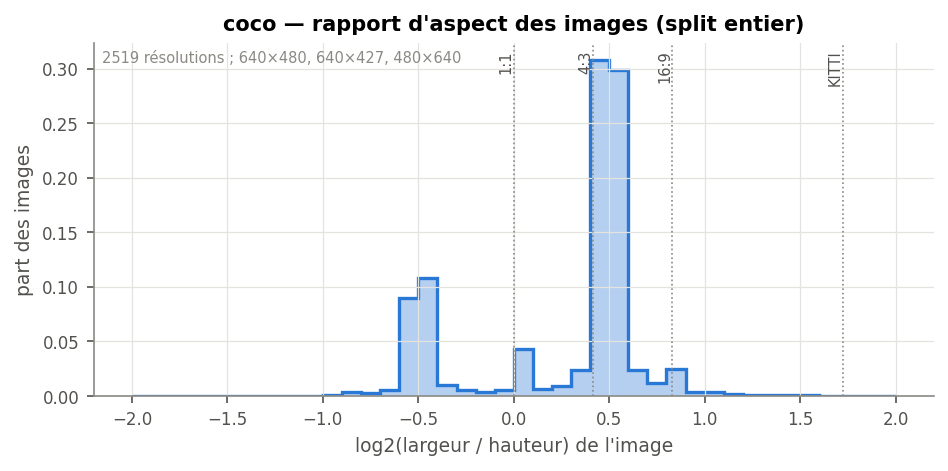

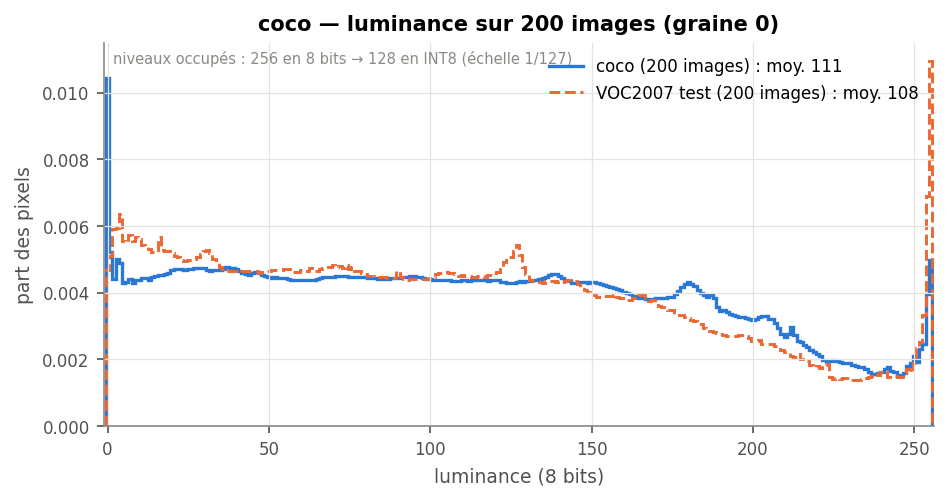

In [8]:
table(DS.md_images)
show("resolutions")
show("intensites")

## Ancres (T16.9)

Boîtes du groupe train en pixels d'entrée letterbox, ancres de la cfg, de VOC, de
COCO et du k-means (`tools/kmeans_anchors.py`, mêmes `--size` et `--seed`).

| ancres | w,h (px à 416×416) | IoU moyenne |
|---|---|---|
| VOC (tiny-yolov2-voc) | `35,38  109,141  212,364  301,164  532,337` | 0,3998 |
| VOC (tiny-yolov3-voc) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,5497 |
| COCO (tiny-yolov3-coco) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,5497 |
| cfg du jeu (tiny-yolov3-coco) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,5497 |
| k-means k = 5 (graine 0) | `16,18  45,59  128,82  109,185  284,241` | 0,5013 |
| k-means k = 6 (graine 0) | `14,17  42,46  64,119  148,76  145,202  312,247` | 0,5249 |

849 949 boîtes non-difficult du groupe train, letterbox 416×416.

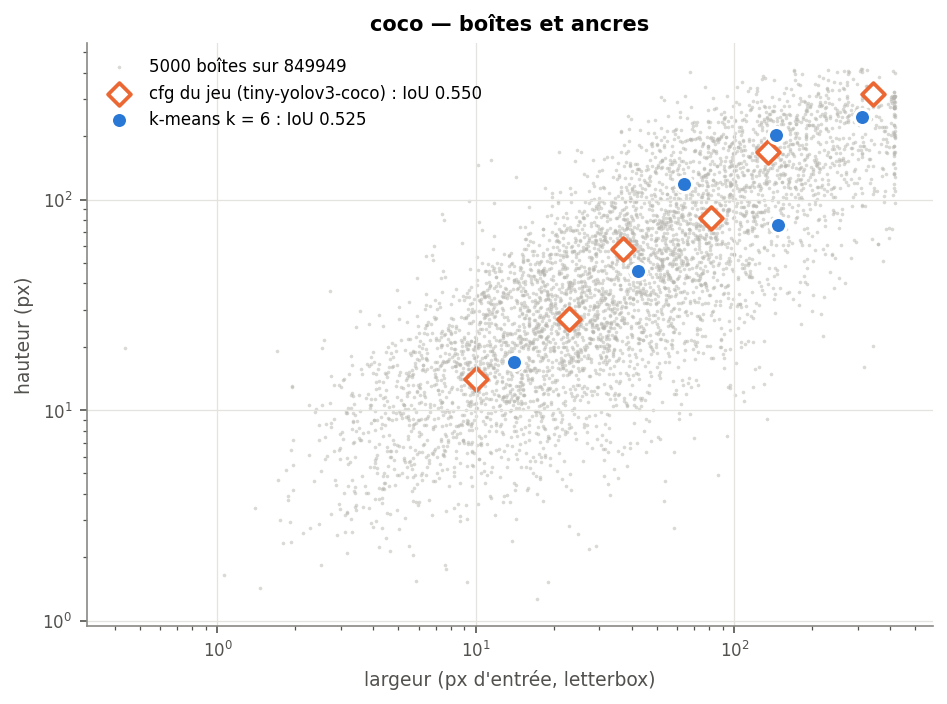

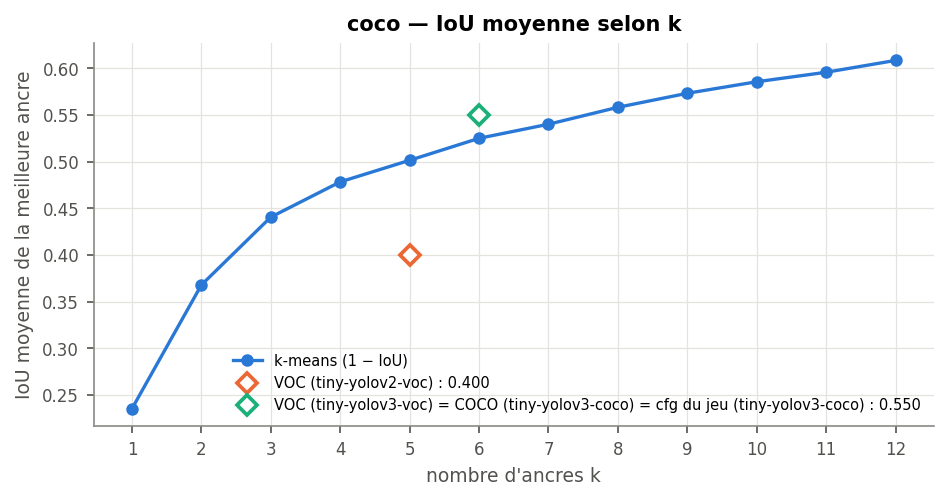

In [9]:
table(DS.md_ancres)
show("ancres")
show("ancres_k")

## Qualité des annotations (T16.10)

Boîtes retirées ou rognées par le chargeur, dégénérées, doublons, régions retirées ;
l'analyse signale, elle ne corrige pas (une correction passe par M11).

| partie | retirées (make_sample) | rognées | côté < 2 px (orig. / entrée) | doublons (IoU > 0,95) | régions retirées par le chargeur |
|---|---|---|---|---|---|
| train2017 | — | 1 165 | 887 / 4 275 | 66 | — |
| val2017 | — | 34 | 44 / 212 | 2 | — |
| ensemble | — | 1 199 | 931 / 4 487 | 68 | — |

80281 : score 10 (retirées 0, rognées 0, dégénérées 10, doublons 0)
253796 : score 7 (retirées 0, rognées 0, dégénérées 7, doublons 0)
201706 : score 6 (retirées 0, rognées 0, dégénérées 0, doublons 3)
296176 : score 6 (retirées 0, rognées 0, dégénérées 6, doublons 0)
99844 : score 6 (retirées 0, rognées 0, dégénérées 0, doublons 3)
562818 : score 5 (retirées 0, rognées 0, dégénérées 5, doublons 0)
250953 : score 4 (retirées 0, rognées 0, dégénérées 4, doublons 0)
254449 : score 4 (retirées 0, rognées 0, dégénérées 4, doublons 0)
304047 : score 4 (retirées 0, rognées 0, dégénérées 0, doublons 2)
396481 : score 4 (retirées 0, rognées 0, dégénérées 4, doublons 0)


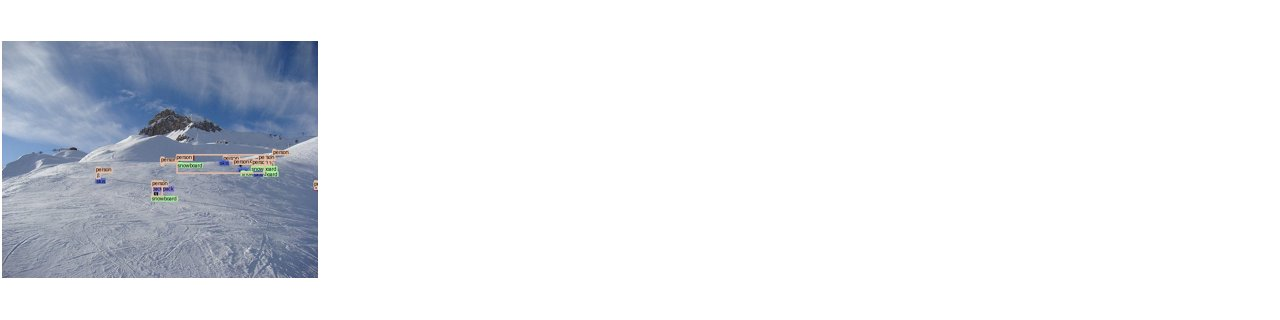

In [10]:
table(DS.md_qualite)
sus = DS.whole(STATS).get("qualite", {}).get("suspects", [])
for d in sus:
    print(f"{d['id']} : score {d['score']} (retirées {d['retirées']}, rognées "
          f"{d['rognées']}, dégénérées {d['dégénérées']}, doublons {d['doublons']})")
sheet = STATS.get("galerie", {}).get("planches", {}).get("suspectes")
if sheet:
    display(Img(filename=str(Path(OUT, sheet))))

## Écart entre splits et couverture hors domaine (T16.11)

Distance en variation totale entre train et test, par grandeur ; part des objets qui
ont une classe VOC ou COCO (ce qu'évaluent les notebooks hors domaine de T14.5).

| grandeur (train ↔ test) | variation totale |
|---|---|
| classes | 0,028 |
| area_in | 0,011 |
| w_in | 0,011 |
| h_in | 0,014 |
| aspect | 0,013 |
| per_image | 0,034 |

| split | classes du modèle | objets couverts | part | évalués (non-difficult) |
|---|---|---|---|---|
| train2017 | VOC | 492 812 | 57,3 % | 485 495 |
| train2017 | COCO | 860 001 | 100,0 % | 849 949 |
| val2017 | VOC | 20 950 | 57,0 % | 20 631 |
| val2017 | COCO | 36 781 | 100,0 % | 36 335 |

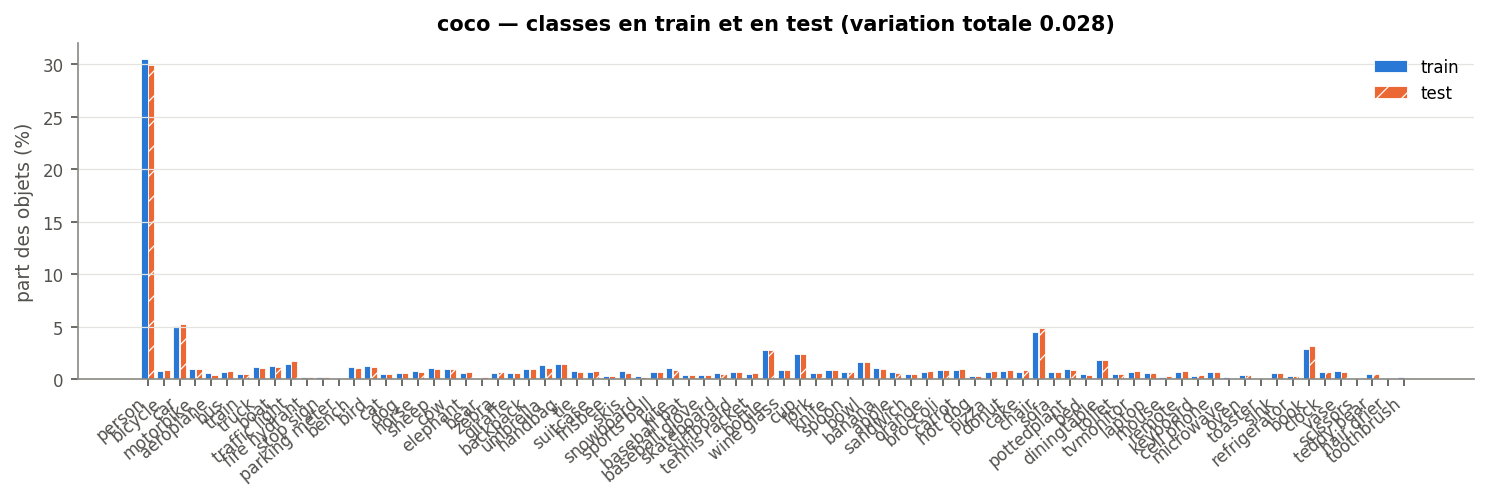

In [11]:
table(DS.md_ecart)
show("ecart")

## Question propre au jeu

Quelle part des objets est petite (< 32²) une fois réduite à 416 ? (renvoi : T11.1)

In [12]:
g = DS.whole(STATS)["geometrie"]
for mode in ("orig", "letterbox", "stretch"):
    c = g[mode]["coco"]
    print(f"{mode:9s} : petits {100 * c[0] / max(sum(c), 1):.1f} %, moyens "
          f"{100 * c[1] / max(sum(c), 1):.1f} %, grands {100 * c[2] / max(sum(c), 1):.1f} %")
if DS.group(STATS, "test").get("comptes"):
    print(f"iscrowd (test) : {DS.group(STATS, 'test')['comptes']['crowd']}")

orig      : petits 31.5 %, moyens 35.2 %, grands 33.4 %
letterbox : petits 44.3 %, moyens 33.4 %, grands 22.3 %
stretch   : petits 38.6 %, moyens 34.6 %, grands 26.8 %
iscrowd (test) : 446


## Résumé

In [13]:
table(DS.md_synthese)
print(f"sorties : {OUT}/ (stats.json, stats.md, figures/, galerie/) ; "
      f"révision {TRACE['rev']}")
print("commandes équivalentes :")
for c in C.HISTORY:
    print("  " + c)

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train2017 | 118 287 | 860 001 | 10 052 | 1 021 | 4 / 93 | 44,3 % | 13x13 33,8 % · 26x26 14,6 % | 25,83 % | 0 / 0 |
| val2017 | 5 000 | 36 781 | 446 | 48 | 4 / 63 | 44,5 % | 13x13 34,1 % · 26x26 14,2 % | 25,61 % | 0 / 0 |
| ensemble | 123 287 | 896 782 | 10 498 | 1 069 | 4 / 93 | 44,3 % | 13x13 33,8 % · 26x26 14,6 % | 25,82 % | 0 / 0 |

sorties : build/notebooks/coco/stats/ (stats.json, stats.md, figures/, galerie/) ; révision 3263136
commandes équivalentes :
  python tools/data_stats.py --dataset coco --size 416 --resize letterbox --net tiny-yolov3-coco --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/coco/stats
